# 6ª Prática de Laboratório — Circuitos 2 (EL216)
### Análise teórica do amplificador emissor comum

**Autor:** Romário Jonas O. Veloso  
**Data:** 16/11/2026  
**Instituição:** Universidade Federal de Pernambuco — Departamento de Eletrônica e Sistemas  
**Referência:** *6ª Prática de Laboratório*, Prof. Hermano Cabral, pp. 6–7.

**Escopo:** grandes sinais, pequenos sinais, parâmetros $g$ do quadripolo e curvas teóricas. Valores conforme o roteiro; as medições e o MMEQ pertencem à etapa pós-laboratorial.

## Dados do roteiro

$V_{CC}=12\,\mathrm V$; $R_C=4{,}7\,\mathrm{k\Omega}$; $R_E=470\,\Omega$; $R_f=150\,\mathrm{k\Omega}$; $\beta=150$; $V_{BE0}=0{,}7\,\mathrm V$.  
$C_{C1}=C_{C2}=C_E=10\,\mu\mathrm F$; $f=5\,\mathrm{kHz}$; $g_m=30I_C$; $r_\pi=\beta/g_m$.  
Entrada: $V_1=30\,\mathrm{mV}$ (**amplitude**, no exemplo teórico). Cargas: $R_L=680\,\Omega$ e $R_L=50\,680\,\Omega$.

### Circuito do roteiro (p. 2)

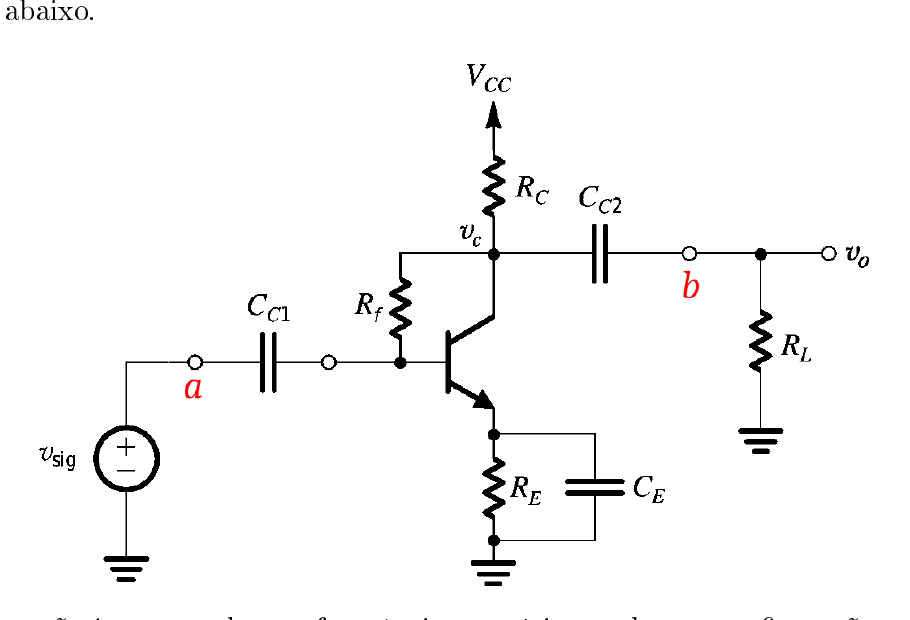

*O transistor 2N3904 NPN substitui o NPN genérico da figura; $R_L$ é variado apenas na análise teórica.*

In [1]:
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display

sp.init_printing()
VCC_val, RC_val, RE_val, Rf_val = 12.0, 4700.0, 470.0, 150000.0
beta_val, VBE_val = 150.0, 0.7
C_val, f_val, V1_amp = 10e-6, 5000.0, 30e-3
cargas = [680.0, 50680.0]

## 1. Grandes sinais — ponto de operação DC

Capacitores **abertos**; $I_C=\beta I_B$, $I_E=(\beta+1)I_B$ e $V_B=V_E+V_{BE0}$.

Pela LKT na malha de polarização:

$$V_{CC}=I_E(R_C+R_E)+I_BR_f+V_{BE0}.$$

In [2]:
VCC, RC, RE, Rf, beta, VBE0, IB = sp.symbols('V_CC R_C R_E R_f beta V_BE0 I_B', positive=True)

malha = sp.Eq(VCC, (beta+1)*IB*(RC+RE) + Rf*IB + VBE0)
IB_expr = sp.factor(sp.solve(malha, IB)[0])
IC_expr = beta * IB_expr
IE_expr = (beta+1) * IB_expr
VE_expr = sp.factor(RE*IE_expr)
VB_expr = VBE0 + VE_expr
VC_expr = sp.factor(VCC - RC*IE_expr)

for nome, expressao in [('I_B',IB_expr),('I_C',IC_expr),('I_E',IE_expr),
                        ('V_E',VE_expr),('V_B',VB_expr),('V_C',VC_expr)]:
    display(sp.Eq(sp.Symbol(nome), expressao))

             -(V_BE0 - V_CC)         
I_B = ───────────────────────────────
      R_C⋅β + R_C + R_E⋅β + R_E + R_f

            -β⋅(V_BE0 - V_CC)        
I_C = ───────────────────────────────
      R_C⋅β + R_C + R_E⋅β + R_E + R_f

         -(V_BE0 - V_CC)⋅(β + 1)     
I_E = ───────────────────────────────
      R_C⋅β + R_C + R_E⋅β + R_E + R_f

       -R_E⋅(V_BE0 - V_CC)⋅(β + 1)   
V_E = ───────────────────────────────
      R_C⋅β + R_C + R_E⋅β + R_E + R_f

          R_E⋅(V_BE0 - V_CC)⋅(β + 1)           
V_B = - ─────────────────────────────── + V_BE0
        R_C⋅β + R_C + R_E⋅β + R_E + R_f        

      R_C⋅V_BE0⋅β + R_C⋅V_BE0 + R_E⋅V_CC⋅β + R_E⋅V_CC + R_f⋅V_CC
V_C = ──────────────────────────────────────────────────────────
                   R_C⋅β + R_C + R_E⋅β + R_E + R_f              

### Resultados numéricos (LAB)

In [3]:
subs_dc = {VCC:VCC_val, RC:RC_val, RE:RE_val, Rf:Rf_val,
           beta:beta_val, VBE0:VBE_val}
IB_dc = float(IB_expr.subs(subs_dc))
IC_dc = float(IC_expr.subs(subs_dc))
IE_dc = float(IE_expr.subs(subs_dc))
VE_dc = float(VE_expr.subs(subs_dc))
VB_dc = float(VB_expr.subs(subs_dc))
VC_dc = float(VC_expr.subs(subs_dc))

resumo_dc = pd.DataFrame({
    'Grandeza':['I_B','I_C','I_E','V_B','V_C','V_E','V_BE','V_CB','V_CE'],
    'Resultado':[IB_dc*1e6, IC_dc*1e3, IE_dc*1e3, VB_dc, VC_dc, VE_dc,
                 VB_dc-VE_dc, VC_dc-VB_dc, VC_dc-VE_dc],
    'Unidade':['µA','mA','mA','V','V','V','V','V','V']
})
display(resumo_dc.round(5))

ativo = (VB_dc-VE_dc > 0.55) and (VC_dc > VB_dc)
print('Região ativa direta:', 'CONFIRMADA' if ativo else 'NÃO CONFIRMADA')
assert ativo

,Grandeza,Resultado,Unidade
0,I_B,12.14179,µA
1,I_C,1.82127,mA
2,I_E,1.83341,mA
3,V_B,1.56170,V
4,V_C,3.38297,V
5,V_E,0.86170,V
6,V_BE,0.70000,V
7,V_CB,1.82127,V
8,V_CE,2.52127,V


Região ativa direta: CONFIRMADA


## 2. Pequenos sinais — modelo híbrido-$\pi$

Capacitores **em curto** e fonte DC aterrada. A aproximação do roteiro utiliza $v_{be}=V_1$:

$$i_c=g_mv_{be},\qquad i_b=\frac{v_{be}}{r_\pi},\qquad g_m=30I_C,\qquad r_\pi=\frac{\beta}{g_m}.$$

In [4]:
gm_dc = 30*IC_dc
rpi_dc = beta_val/gm_dc
Xc = 1/(2*np.pi*f_val*C_val)
print(f'g_m = {gm_dc:.8f} S = {gm_dc*1e3:.5f} mS')
print(f'r_π = {rpi_dc:.4f} Ω')
print(f'|X_C| (5 kHz, 10 µF) = {Xc:.4f} Ω  [curto aproximado no roteiro]')

g_m = 0.05463806 S = 54.63806 mS
r_π = 2745.3392 Ω
|X_C| (5 kHz, 10 µF) = 3.1831 Ω  [curto aproximado no roteiro]


## 3. Parâmetros $g$ do quadripolo

$$I_1=g_{11}V_1+g_{12}I_2,\qquad V_2=g_{21}V_1+g_{22}I_2.$$

Aplicando LKC às portas **1 (base)** e **2 (coletor)**, com $I_2$ definido **entrando** no quadripolo:

$$I_1=\frac{V_1}{r_\pi}+\frac{V_1-V_2}{R_f},\qquad
I_2=\frac{V_2}{R_C}+\frac{V_2-V_1}{R_f}+g_mV_1.$$

Resolvem-se essas equações simbolicamente para obter $I_1(V_1,I_2)$ e $V_2(V_1,I_2)$.

In [5]:
V1, V2, I1, I2 = sp.symbols('V_1 V_2 I_1 I_2', real=True)
gm, rpi = sp.symbols('g_m r_pi', positive=True)

kcl_1 = sp.Eq(I1, V1/rpi + (V1-V2)/Rf)
kcl_2 = sp.Eq(I2, V2/RC + (V2-V1)/Rf + gm*V1)
resolucao = sp.solve((kcl_1, kcl_2), (I1, V2), dict=True)[0]

G11 = sp.factor(sp.diff(resolucao[I1], V1))
G12 = sp.factor(sp.diff(resolucao[I1], I2))
G21 = sp.factor(sp.diff(resolucao[V2], V1))
G22 = sp.factor(sp.diff(resolucao[V2], I2))
G = sp.Matrix([[G11,G12], [G21,G22]])

display(sp.Eq(sp.Symbol('G'), G, evaluate=False))
print('Ordem: [g11, g12; g21, g22]')

    ⎡R_C⋅gₘ⋅rₚᵢ + R_C + R_f + rₚᵢ    -R_C   ⎤
    ⎢────────────────────────────  ─────────⎥
    ⎢      rₚᵢ⋅(R_C + R_f)         R_C + R_f⎥
G = ⎢                                       ⎥
    ⎢     -R_C⋅(R_f⋅gₘ - 1)         R_C⋅R_f ⎥
    ⎢     ──────────────────       ─────────⎥
    ⎣         R_C + R_f            R_C + R_f⎦

Ordem: [g11, g12; g21, g22]


### Valores numéricos de $g_{11}$, $g_{12}$, $g_{21}$ e $g_{22}$

In [6]:
subs_ac = {RC:RC_val, Rf:Rf_val, gm:gm_dc, rpi:rpi_dc}
g11,g12,g21,g22 = [float(termo.subs(subs_ac)) for termo in (G11,G12,G21,G22)]
g_tabela = pd.DataFrame({
    'Parâmetro':['g11','g12','g21','g22'],
    'Valor':[g11,g12,g21,g22],
    'Unidade':['S','adimensional','adimensional','Ω']
})
display(g_tabela.round(7))
print(f'I₁ = ({g11:.9f}) V₁ + ({g12:.9f}) I₂')
print(f'V₂ = ({g21:.6f}) V₁ + ({g22:.6f}) I₂')

,Parâmetro,Valor,Unidade
0,g11,0.002031,S
1,g12,-0.030381,adimensional
2,g21,-248.966579,adimensional
3,g22,4557.207498,Ω


I₁ = (0.002030698) V₁ + (-0.030381383) I₂
V₂ = (-248.966579) V₁ + (4557.207498) I₂


## 4. Carga, ganho e resistência de entrada

Como $I_2$ entra no quadripolo, para uma carga $R_L$ conectada à saída:

$$I_2=-\frac{V_2}{R_L},\quad A_v=\frac{V_2}{V_1},\quad R_{in}=\frac{V_1}{I_1}.$$

In [7]:
RL = sp.symbols('R_L', positive=True)
Av_expr = sp.factor(G21*RL/(RL+G22))
Rin_expr = sp.factor(1/(G11-G12*Av_expr/RL))
V2_expr = sp.factor(Av_expr*V1)
I1_expr = sp.factor(V1/Rin_expr)

for nome, expr in [('A_v',Av_expr),('R_in',Rin_expr)]:
    display(sp.Eq(sp.Symbol(nome),expr))

       -R_C⋅R_L⋅(R_f⋅gₘ - 1)    
Aᵥ = ───────────────────────────
     R_C⋅R_L + R_C⋅R_f + R_L⋅R_f

                     rₚᵢ⋅(R_C⋅R_L + R_C⋅R_f + R_L⋅R_f)                
Rᵢₙ = ────────────────────────────────────────────────────────────────
      R_C⋅R_L⋅gₘ⋅rₚᵢ + R_C⋅R_L + R_C⋅R_f + R_C⋅rₚᵢ + R_L⋅R_f + R_L⋅rₚᵢ

### Resultados para as duas cargas (LAB)

$V_1=30\,\mathrm{mV}$ é a **amplitude de pico teórica**. O sinal de $V_2$ indica inversão de fase.

In [8]:
def calc_carga(rl):
    av = g21*rl/(rl+g22)
    rin = 1/(g11-g12*av/rl)
    v2 = av*V1_amp
    i1 = V1_amp/rin
    i2 = -v2/rl
    return dict(RL_ohm=rl, Av=av, V2_V=v2, V2_mod_V=abs(v2),
                I1_uA=i1*1e6, I2_mA=i2*1e3, Rin_ohm=rin)

dados_cargas = pd.DataFrame([calc_carga(rl) for rl in cargas])
display(dados_cargas.rename(columns={
    'RL_ohm':'R_L (Ω)','Av':'A_v (V/V)', 'V2_V':'V_2 (V; sinal)',
    'V2_mod_V':'|V_2| (V)', 'I1_uA':'I_1 (µA)',
    'I2_mA':'I_2 (mA)', 'Rin_ohm':'R_in (Ω)' }).round(5))

,R_L (Ω),A_v (V/V),V_2 (V; sinal),|V_2| (V),I_1 (µA),I_2 (mA),R_in (Ω)
0,680.0,-32.32587,-0.96978,0.96978,17.59278,1.42614,1705.24453
1,50680.0,-228.42621,-6.85279,6.85279,56.81285,0.13522,528.04951


## 5. Curvas em função de $R_L$

Representação do **modelo linear** para $680\leq R_L\leq50\,680\,\Omega$, com $V_1=30\,\mathrm{mV}$.

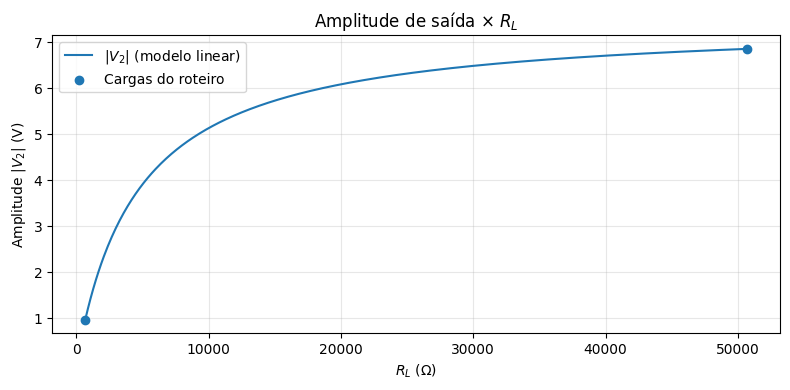

In [9]:
rl_vetor = np.linspace(680,50680,500)
av_vetor = g21*rl_vetor/(rl_vetor+g22)
rin_vetor = 1/(g11-g12*av_vetor/rl_vetor)
v2_vetor = av_vetor*V1_amp
i1_vetor = V1_amp/rin_vetor

plt.figure(figsize=(8,4))
plt.plot(rl_vetor, np.abs(v2_vetor), label=r'$|V_2|$ (modelo linear)')
plt.scatter(dados_cargas.RL_ohm, dados_cargas.V2_mod_V, zorder=4, label='Cargas do roteiro')
plt.xlabel(r'$R_L$ (Ω)'); plt.ylabel(r'Amplitude $|V_2|$ (V)')
plt.title(r'Amplitude de saída × $R_L$')
plt.grid(True,alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

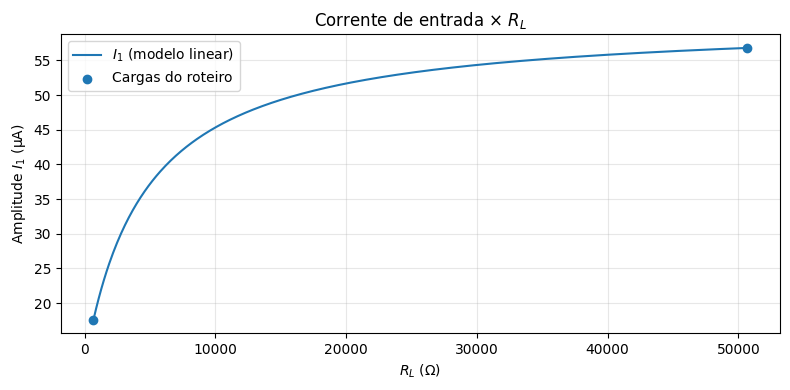

In [10]:
plt.figure(figsize=(8,4))
plt.plot(rl_vetor, i1_vetor*1e6, label=r'$I_1$ (modelo linear)')
plt.scatter(dados_cargas.RL_ohm, dados_cargas.I1_uA, zorder=4, label='Cargas do roteiro')
plt.xlabel(r'$R_L$ (Ω)'); plt.ylabel(r'Amplitude $I_1$ (µA)')
plt.title(r'Corrente de entrada × $R_L$')
plt.grid(True,alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

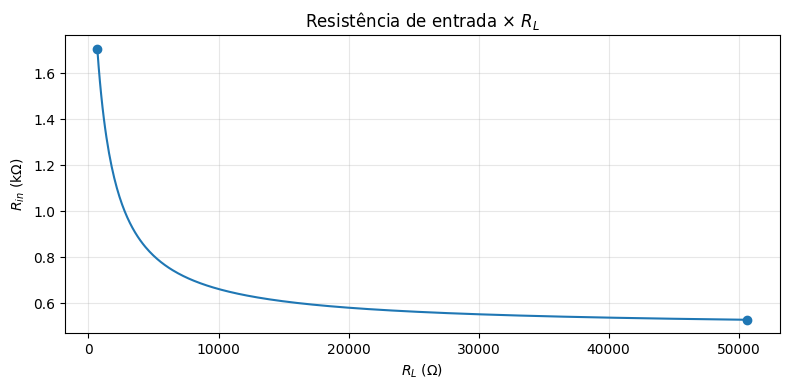

In [11]:
plt.figure(figsize=(8,4))
plt.plot(rl_vetor,rin_vetor/1e3)
plt.scatter(dados_cargas.RL_ohm, dados_cargas.Rin_ohm/1e3, zorder=4)
plt.xlabel(r'$R_L$ (Ω)'); plt.ylabel(r'$R_{in}$ (kΩ)')
plt.title(r'Resistência de entrada × $R_L$')
plt.grid(True,alpha=.3); plt.tight_layout(); plt.show()

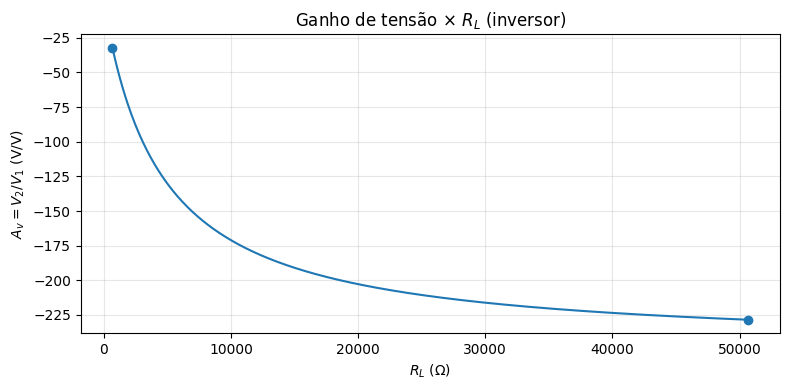

In [12]:
plt.figure(figsize=(8,4))
plt.plot(rl_vetor,av_vetor)
plt.scatter(dados_cargas.RL_ohm, dados_cargas.Av, zorder=4)
plt.xlabel(r'$R_L$ (Ω)'); plt.ylabel(r'$A_v=V_2/V_1$ (V/V)')
plt.title(r'Ganho de tensão × $R_L$ (inversor)')
plt.grid(True,alpha=.3); plt.tight_layout(); plt.show()

## 6. Verificação dos resultados

Conferência algébrica das duas equações do quadripolo e dos valores numéricos de polarização.

In [13]:
assert np.isclose(IE_dc, IC_dc+IB_dc)
assert np.isclose(VC_dc, VCC_val-RC_val*(IC_dc+IB_dc))
assert sp.simplify(G11 - (1/rpi+(1+gm*RC)/(RC+Rf))) == 0
assert sp.simplify(G12 + RC/(RC+Rf)) == 0
assert sp.simplify(G21 - RC*(1-gm*Rf)/(RC+Rf)) == 0
assert sp.simplify(G22 - RC*Rf/(RC+Rf)) == 0
for r in dados_cargas.itertuples():
    v1=V1_amp; v2=r.V2_V; i1=r.I1_uA*1e-6; i2=r.I2_mA*1e-3
    assert np.isclose(i1,g11*v1+g12*i2)
    assert np.isclose(v2,g21*v1+g22*i2)
print('Verificações DC, parâmetros g e equações do quadripolo: OK')

Verificações DC, parâmetros g e equações do quadripolo: OK


**Limites da previsão:** os gráficos usam o modelo linear com capacitores idealizados como curtos. Na carga alta, a tensão de saída prevista pode ultrapassar a excursão possível do coletor, produzindo saturação/distorção no circuito real.

**Atenção às unidades:** na seção teórica o roteiro utiliza **amplitude de 30 mV**; na medição física solicita **30 mV pico a pico**. Não são a mesma condição: $30\,\mathrm{mVpp}=15\,\mathrm{mV}$ de pico para uma senoide.

*Fonte: 6ª Prática de Laboratório, EL216 — Circuitos 2, UFPE, pp. 6–8.*